In [1]:
%store -r

In [2]:
import boto3
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from io import BytesIO
from PIL import Image

import sagemaker
from sagemaker.predictor import Predictor
from sagemaker.serializers import IdentitySerializer
from sagemaker.deserializers import CSVDeserializer, JSONDeserializer

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml


In [18]:
# Training manifest written by 5_Classification_Model
manifest_obj = boto3.client("s3").get_object(Bucket=bucket, Key=training_manifest_remote_path)
training_manifest = pd.read_parquet(BytesIO(manifest_obj["Body"].read()))
non_cat_sample = training_manifest[(training_manifest["split"]=="test") & (training_manifest["label"]==0)].sample(5)
cat_sample = training_manifest[(training_manifest["split"]=="test") & (training_manifest["label"]==1)].sample(5)

input_sample = pd.concat([non_cat_sample, cat_sample])["remote_path"]

In [19]:
np.random.shuffle(input_sample.to_numpy())
input_sample

38410    s3://sagemaker-us-east-1-298748835671/cat-land...
38062    s3://sagemaker-us-east-1-298748835671/cat-land...
24988    s3://sagemaker-us-east-1-298748835671/cat-land...
21835    s3://sagemaker-us-east-1-298748835671/cat-land...
26035    s3://sagemaker-us-east-1-298748835671/cat-land...
4300     s3://sagemaker-us-east-1-298748835671/cat-land...
8799     s3://sagemaker-us-east-1-298748835671/cat-land...
41631    s3://sagemaker-us-east-1-298748835671/cat-land...
34574    s3://sagemaker-us-east-1-298748835671/cat-land...
4011     s3://sagemaker-us-east-1-298748835671/cat-land...
Name: remote_path, dtype: object

In [20]:
input_sample.shape

(10,)

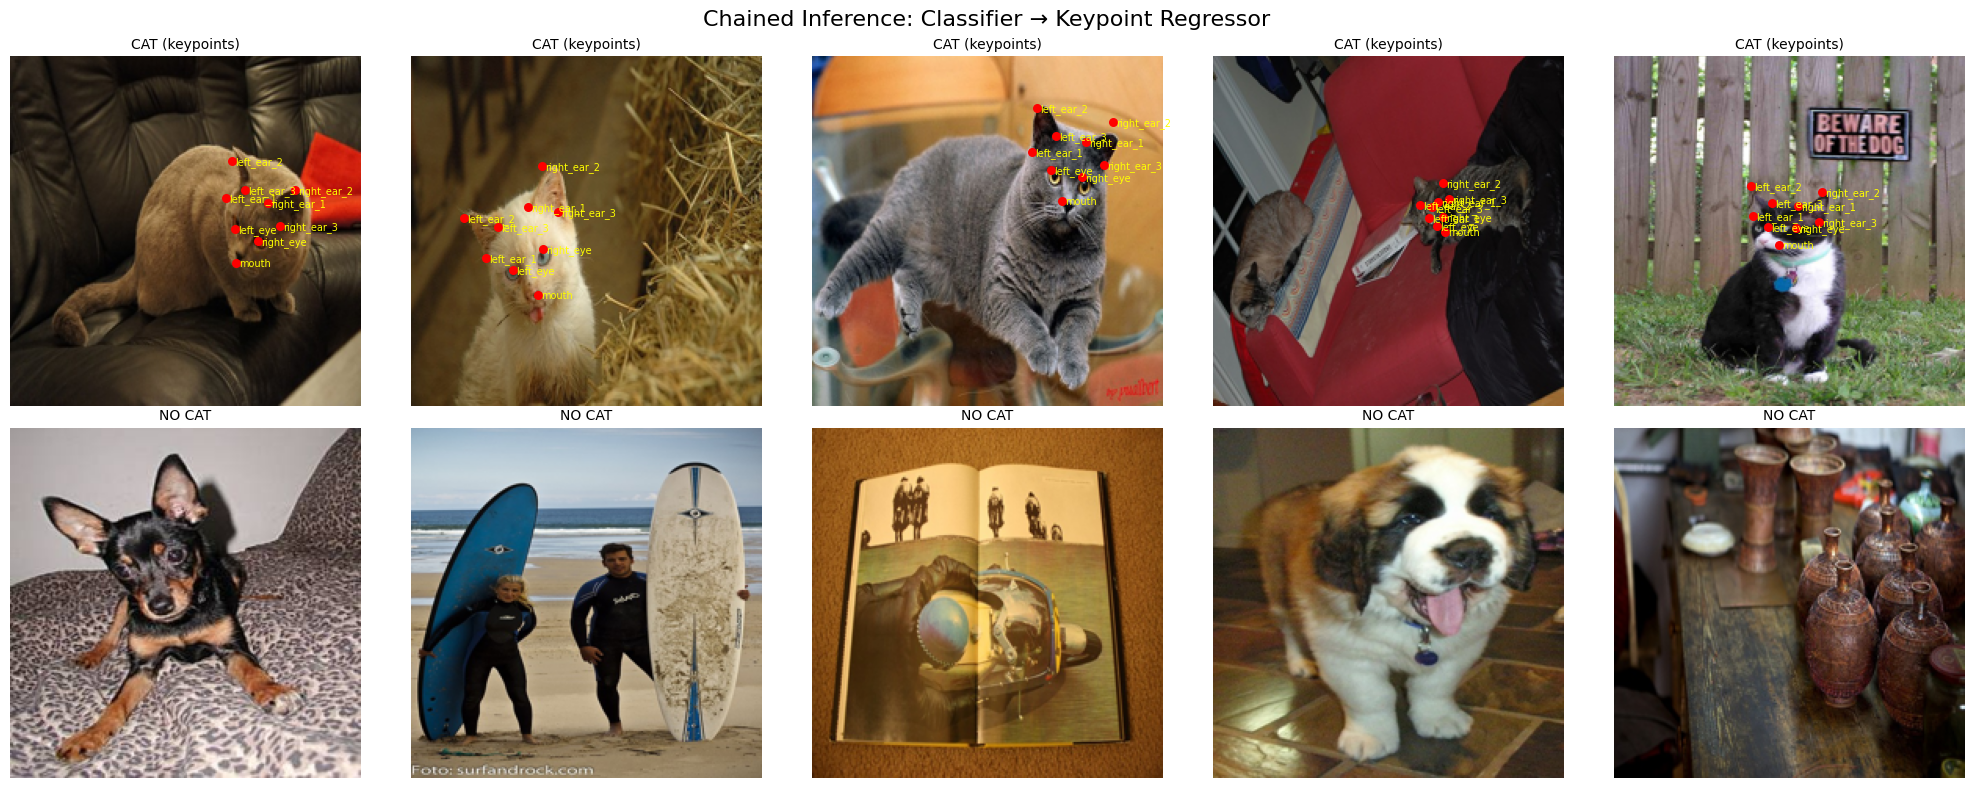

In [21]:
# ---------------------------------------------------------------------
# Config
# ---------------------------------------------------------------------
IMAGE_SIZE = 224

S3_URIS = input_sample

KEYPOINT_NAMES = [
    "left_eye", "right_eye", "mouth",
    "left_ear_1", "left_ear_2", "left_ear_3",
    "right_ear_1", "right_ear_2", "right_ear_3",
]

sagemaker_session = sagemaker.Session()
# Endpoints deployed by 6_Monitoring
classifier_endpoint_name = cls_endpoint_name
kp_endpoint_name = kp_endpoint_name
# ---------------------------------------------------------------------
# SageMaker endpoints: both receive the raw JPEG, as a production client would send it
# ---------------------------------------------------------------------
classifier_predictor = Predictor(
    endpoint_name=classifier_endpoint_name,
    sagemaker_session=sagemaker_session,
    serializer=IdentitySerializer("image/jpeg"),
    deserializer=CSVDeserializer(),
)

kp_predictor = Predictor(
    endpoint_name=kp_endpoint_name,
    sagemaker_session=sagemaker_session,
    serializer=IdentitySerializer("image/jpeg"),
    deserializer=JSONDeserializer(),
)

# ---------------------------------------------------------------------
# Utilities
# ---------------------------------------------------------------------
def load_image_bytes_from_s3(s3_uri: str) -> bytes:
    bucket, key = s3_uri.replace("s3://", "").split("/", 1)
    s3 = boto3.client("s3")
    return s3.get_object(Bucket=bucket, Key=key)["Body"].read()

def run_classifier(image_bytes: bytes):
    """
    Returns:
        predicted_class (int): 0 = non-cat, 1 = cat
        cat_prob (float)
    """
    # CSV response: predicted class, cat probability, then request-image statistics
    response = classifier_predictor.predict(image_bytes)[0]
    return int(response[0]), float(response[1])

def run_keypoint_regressor(image_bytes: bytes) -> dict:
    """
    Returns:
        Dict[str, Dict[str, float]] mapping keypoint -> {x, y}, normalized to [0, 1]
    """
    response = kp_predictor.predict(image_bytes)
    return {name: response[name] for name in KEYPOINT_NAMES}

# ---------------------------------------------------------------------
# Run pipeline
# ---------------------------------------------------------------------
results = []

for s3_uri in S3_URIS:
    image_bytes = load_image_bytes_from_s3(s3_uri)
    image_resized = Image.open(BytesIO(image_bytes)).convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))

    pred_class, cat_prob = run_classifier(image_bytes)
    keypoints = None
    if pred_class == 1:
        keypoints = run_keypoint_regressor(image_bytes)
        
    results.append({
		"s3_uri": s3_uri,
		"image": image_resized,
		"label": pred_class,
		"cat_prob": cat_prob,
		"keypoints": keypoints,
	})

# ---------------------------------------------------------------------
# Select 5 cats + 5 non-cats
# ---------------------------------------------------------------------
cats = [r for r in results if r["label"] == 1][:5]
noncats = [r for r in results if r["label"] == 0][:5]

selected = cats + noncats
#assert len(selected) == 10, "Need at least 5 cats and 5 non-cats"

# ---------------------------------------------------------------------
# Visualization
# ---------------------------------------------------------------------
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for ax, item in zip(axes, selected):
    ax.imshow(item["image"])
    ax.axis("off")

    if item["label"] == 1:
        for name, coords in item["keypoints"].items():
            x = coords["x"] * IMAGE_SIZE
            y = coords["y"] * IMAGE_SIZE
            ax.scatter(x, y, c="red", s=30)
            ax.text(x + 2, y + 2, name, fontsize=7, color="yellow")
            ax.set_title("CAT (keypoints)", fontsize=10)
    else:
        ax.set_title("NO CAT", fontsize=10)

plt.suptitle("Chained Inference: Classifier → Keypoint Regressor", fontsize=16)
plt.tight_layout()
plt.show()